# 01 — Audit des données et baseline de retrieval sur FinanceBench

**Projet :** système RAG d'analyse de rapports financiers (cible : équipes Audit / Risk / Data-AI des Big Four)
**Ce notebook :** de zéro jusqu'à un tableau comparatif chiffré de 5 méthodes de recherche (une baseline aléatoire + 4 stratégies).
| | |
|---|---|
| **Question de recherche** | Est-ce que la recherche hybride (BM25 + vectorielle) avec reranking retrouve mieux la page de preuve qu'une recherche vectorielle simple ? |
| **Entrées** | FinanceBench (150 questions, PDF de rapports de sociétés américaines) |
| **Sorties** | Jeux dev/test figés, index vectoriel, tableau recall@k et MRR, analyse d'erreurs |
| **Ce notebook ne fait PAS** | Générer des réponses avec un LLM (c'est le notebook 02). Ici on mesure uniquement si on retrouve la bonne page. |

## Sommaire
0. Configuration et reproductibilité (dont 0.3 : mode complet ou léger)
1. Chargement des données
2. Audit des données
3. Sélection des documents
4. Téléchargement et audit des PDF
5. Calibration des numéros de page
6. Vérité terrain et séparation dev / test
7. Découpage en chunks
8. Embeddings et index vectoriel
9. Les stratégies de retrieval
10. Les métriques
11. Résultats sur le jeu dev
12. Analyse d'erreurs
13. Évaluation finale sur le jeu test (verrouillée)
14. Sauvegarde et conclusion

## Comment lire ce notebook
Chaque section suit le même schéma, comme dans un vrai projet de data science :
1. **Objectif** : ce que la section doit produire.
2. **Pour comprendre** : l'idée derrière, en langage simple.
3. **Code**.
4. **Lecture des résultats** : ce qu'il faut vérifier, avec des espaces *« Mes observations »* que tu remplis toi-même.

## Trois règles du projet
- **Reproductibilité** : une graine fixe (`SEED`), une configuration unique en section 0, tout est sauvegardé sur Drive.
- **Pas de fuite** : on règle les paramètres sur *dev*. Le jeu *test* ne sert qu'une fois, à la fin.
- **Tout choix est écrit** dans `DECISIONS.md` (le quoi, le pourquoi, la date).

## 0. Configuration et reproductibilité

**Objectif :** installer les outils légers, repérer où ranger les fichiers, centraliser *tous* les paramètres, puis décider (section 0.3) si les modèles lourds sont installables.

**Pour comprendre :**
- Un projet reproductible se relance de zéro et donne les mêmes résultats. Pour cela : une graine aléatoire fixe, des versions de bibliothèques notées, et des paramètres jamais « cachés » au milieu du code.
- Sur Colab, les fichiers locaux disparaissent à la fin de la session. Tout ce qui compte (PDF, index, résultats) est donc écrit sur **Google Drive**.
- **Deux modes de rangement**, détectés automatiquement :
  - **mode dépôt** (recommandé) : si le notebook est dans `notebooks/` d'un dépôt qui contient `pyproject.toml`, les données lourdes vont dans `data/` (ignoré par Git) et les petits fichiers dans `eval/` et `results/` (versionnés) ;
  - **mode simple** : sinon, tout est rangé dans un dossier `rag_financebench`.
- **Installation avec `%pip`** (et non `!pip`) : elle installe les paquets dans l'environnement Python *du notebook*. Avec `!pip`, Jupyter peut installer ailleurs et tu obtiens ensuite des erreurs d'import incompréhensibles.
- **Règle d'or :** les cellules s'exécutent *dans l'ordre*. La section 1 utilise des variables créées ici : si tu sautes cette section, tu obtiens `NameError`.
- Les paramètres (taille des chunks, modèles, k) sont des **hyperparamètres** : on les change ici, nulle part ailleurs.

In [1]:
%pip install -q pymupdf rank_bm25 matplotlib pandas numpy requests

  Consider adding this directory to PATH or, if you prefer to suppress this warning, use --no-warn-script-location.
Note: you may need to restart the kernel to use updated packages.


In [2]:
import os, re, json, random, time, platform, hashlib
from pathlib import Path
import numpy as np, pandas as pd, requests, io
import matplotlib.pyplot as plt
import pymupdf

# ---------- Où sont les fichiers ? ----------
def find_repo_root(start):
    """Remonte les dossiers parents jusqu'à la racine du dépôt (pyproject.toml + notebooks/)."""
    for p in [start, *start.parents]:
        if (p / "pyproject.toml").exists() and (p / "notebooks").is_dir():
            return p
    return None

try:
    from google.colab import drive
    drive.mount("/content/drive")
    IN_COLAB = True
    candidates = [Path("/content/drive/MyDrive") / n for n in ("RAG-Financier", "rag-finance")]
    REPO = next((c for c in candidates if (c / "pyproject.toml").exists()), None)
except ImportError:
    IN_COLAB = False
    REPO = find_repo_root(Path.cwd().resolve())

if REPO is not None:                                      # mode dépôt (recommandé)
    ROOT = REPO
    RAW_DIR, PDF_DIR, IDX_DIR = REPO / "data" / "raw", REPO / "data" / "pdfs", REPO / "data" / "index"
    EVAL_DIR, RES_DIR = REPO / "eval", REPO / "results"   # petits fichiers, versionnés avec Git
    MODE = "dépôt"
else:                                                     # mode simple : tout dans un seul dossier
    ROOT = Path("/content/drive/MyDrive/rag_financebench") if IN_COLAB else Path("./rag_financebench")
    RAW_DIR, PDF_DIR, EVAL_DIR, IDX_DIR, RES_DIR = (ROOT / d for d in ["raw", "pdfs", "eval", "index", "results"])
    MODE = "simple"
for d in (RAW_DIR, PDF_DIR, EVAL_DIR, IDX_DIR, RES_DIR):
    d.mkdir(parents=True, exist_ok=True)

# ---------- Configuration : TOUS les paramètres sont ici ----------
SEED = 42
GITHUB_RAW = "https://raw.githubusercontent.com/patronus-ai/financebench/main/"

# sélection des documents
N_PAIR_COMPANIES = 6     # sociétés dont on garde 2 documents (années proches)
N_SINGLES = 6            # documents isolés d'autres sociétés / secteurs

# découpage
CHUNK_SIZE, CHUNK_OVERLAP = 1200, 200   # en caractères
ADD_HEADER = True        # préfixe "[doc | page]" ajouté au texte de chaque chunk

# modèles
EMB_MODEL = "BAAI/bge-base-en-v1.5"
QUERY_PREFIX = "Represent this sentence for searching relevant passages: "
RERANK_MODEL = "BAAI/bge-reranker-base"

# retrieval
TOP_N = 50               # nombre de candidats gardés par chaque méthode
RERANK_TOP = 30          # nombre de candidats donnés au reranker
RRF_K = 60               # constante de la fusion RRF

# évaluation
KS = [1, 3, 5, 10]
DEV_FRAC = 0.7
RUN_TEST = False         # NE PASSER À True QU'UNE SEULE FOIS, à la toute fin

random.seed(SEED); np.random.seed(SEED)
print(f"Rangement : {MODE} | Colab : {IN_COLAB}")
print("Racine :", ROOT.resolve())

Rangement : dépôt | Colab : False
Racine : /home/cd9cacb7-c7af-487a-bd59-e254c9cb864f/RAG-Financier


### 0.3 Modèles : mode complet ou mode léger

**Pourquoi cette étape :** les modèles d'embeddings et de reranking demandent **PyTorch**, qui pèse plusieurs gigaoctets. Sur un petit espace disque (compte Jupyter gratuit, quota de stockage), l'installation échoue avec `Disk quota exceeded`. Le notebook s'adapte donc à ton environnement :

| Mode | Condition | Méthodes évaluées |
|---|---|---|
| **Complet** | Colab (GPU, gros disque) ou machine avec plusieurs Go libres | random, bm25, dense, hybrid, hybrid+rerank |
| **Léger** | espace limité : on n'installe pas PyTorch | random, bm25 |

- Les sections 1 à 7 (données, PDF, calibration, dev/test, chunks) et la baseline **BM25** n'ont besoin d'aucun paquet lourd : elles tournent partout.
- Le mode est **détecté automatiquement** : si `torch`, `sentence-transformers` et `chromadb` sont installés, c'est le mode complet.
- `INSTALL_MODELS` : sur Colab, il vaut `True` et la cellule installe les paquets. Ailleurs, il vaut `False` : mets `True` seulement si tu es sûr d'avoir la place (compte au moins 5 Go).
- Si tu veux le mode complet sur une machine sans GPU, installe d'abord la version CPU de PyTorch, bien plus légère (environ 200 Mo) : `pip install torch --index-url https://download.pytorch.org/whl/cpu`.

In [3]:
import importlib.util, subprocess, sys

INSTALL_MODELS = IN_COLAB      # True = installe sentence-transformers + chromadb (plusieurs Go)

def has(module):
    try:
        return importlib.util.find_spec(module) is not None
    except (ImportError, ValueError):
        return False

if INSTALL_MODELS:
    for pkg in ("sentence-transformers", "chromadb"):
        r = subprocess.run([sys.executable, "-m", "pip", "install", "-q", pkg], capture_output=True, text=True)
        if r.returncode != 0:                                  # ex. "Disk quota exceeded"
            print("ECHEC d'installation de", pkg, ":\n", r.stderr[-500:])

USE_MODELS = all(has(m) for m in ("torch", "sentence_transformers", "chromadb"))
if USE_MODELS:
    import torch
    DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
else:
    DEVICE = "cpu"

CONFIG = {k: v for k, v in list(globals().items()) if k.isupper() and isinstance(v, (int, float, str, bool, list))}
(RES_DIR / "config.json").write_text(json.dumps(CONFIG, indent=2))

print("Python", platform.python_version(), "| pymupdf", pymupdf.version[0], "| pandas", pd.__version__)
if USE_MODELS:
    print(f"MODE COMPLET : embeddings + reranker actifs | Device : {DEVICE}")
    if DEVICE == "cpu":
        print("ATTENTION : pas de GPU, la section 8 sera lente.")
else:
    print("MODE LEGER : BM25 seul (random + bm25). Les sections 8 et 9 sauteront le dense, l'hybride et le reranker.")
    print("Pour le mode complet : Colab (GPU), ou plus de 5 Go libres puis INSTALL_MODELS = True.")

Python 3.9.12 | pymupdf 1.26.5 | pandas 1.4.2
MODE LEGER : BM25 seul (random + bm25). Les sections 8 et 9 sauteront le dense, l'hybride et le reranker.
Pour le mode complet : Colab (GPU), ou plus de 5 Go libres puis INSTALL_MODELS = True.


### Lecture des résultats
- `Rangement : dépôt` si tu travailles dans ton dossier `RAG-Financier` (c'est ce qu'on veut). `Rangement : simple` signifie que le dépôt n'a pas été trouvé.
- Vérifie les trois chemins affichés : la racine, le dossier des PDF/index (`data/`), et celui de `eval/` et `results/`.
- **`MODE COMPLET`** (Colab) ou **`MODE LEGER`** (petit espace disque) : les deux sont valides, seule la liste des méthodes évaluées change. Dans le mode complet, `Device : cuda` indique que le GPU est actif.
- `config.json` est écrit dans `results/` : il garde la trace exacte des paramètres de *cette* exécution.
- Si l'installation affiche une erreur, relance après *Kernel → Restart* (Jupyter) ou *Exécution → Redémarrer la session* (Colab).

**Mes observations :** ...

> **À noter dans DECISIONS.md :** `SEED = 42`, taille de chunk 1200 / chevauchement 200, modèles choisis (voir le fichier `DECISIONS.md` fourni).

## 1. Chargement des données

**Objectif :** récupérer les deux fichiers de FinanceBench et les garder en copie locale.

**Pour comprendre :**
- `financebench_open_source.jsonl` contient les **150 questions** avec leur réponse et leurs preuves.
- `financebench_document_information.jsonl` contient les **métadonnées des 361 documents** (société, secteur, type, période).
- On les relie par la clé **`doc_name`** (comme une jointure SQL).
- On télécharge **une fois** et on garde une copie dans `raw/` : si GitHub change ou disparaît, ton projet reste reproductible.
- Licence des données : **cc-by-nc-4.0** (usage non commercial). À citer dans le README.

In [4]:
if "RAW_DIR" not in globals():
    raise RuntimeError("Exécute d'abord la section 0 (cellule de configuration) : "
                       "les dossiers et les paramètres n'existent pas encore.")

def load_jsonl(name):
    local = RAW_DIR / name
    if not local.exists():
        r = requests.get(GITHUB_RAW + "data/" + name, timeout=60)
        r.raise_for_status()
        local.write_text(r.text)
    return pd.read_json(local, lines=True)

q = load_jsonl("financebench_open_source.jsonl")
meta = load_jsonl("financebench_document_information.jsonl")

print("questions :", q.shape, "| documents :", meta.shape)
print("colonnes questions :", q.columns.tolist())
print("colonnes documents :", meta.columns.tolist())
assert {"question", "answer", "evidence", "doc_name"} <= set(q.columns)
assert "doc_name" in meta.columns

questions : (150, 11) | documents : (361, 6)
colonnes questions : ['financebench_id', 'company', 'doc_name', 'question_type', 'question_reasoning', 'domain_question_num', 'question', 'answer', 'justification', 'dataset_subset_label', 'evidence']
colonnes documents : ['doc_name', 'company', 'gics_sector', 'doc_type', 'doc_period', 'doc_link']


### Lecture des résultats
Tu dois voir `(150, 11)` pour les questions et `(361, 6)` pour les documents.
Les `assert` sont des **garde-fous** : si le format du dataset change, le notebook s'arrête tout de suite avec un message clair, au lieu de produire des résultats faux plus loin.

**Mes observations :** ...

## 2. Audit des données

**Objectif :** comprendre ce que contient le jeu de données *avant* de construire quoi que ce soit dessus.

**Pour comprendre :**
- Un data scientist ne fait pas confiance à un jeu de données qu'il n'a pas inspecté : valeurs manquantes, doublons, déséquilibres, structure des champs imbriqués.
- La colonne la plus importante est **`evidence`** : une *liste* de dictionnaires (une preuve = un passage + le document + le **numéro de page**). Une question peut avoir plusieurs preuves.
- Le numéro de page sert à mesurer ton système : *est-ce que tu retrouves la page qui contient la preuve ?*

Valeurs manquantes par colonne :
question_reasoning      50
domain_question_num    100
justification           50
dtype: int64 

Doublons sur financebench_id : 0
Sous-ensemble déclaré : ['OPEN_SOURCE'] 

Type de la colonne evidence : list
Clés d'une preuve : ['doc_name', 'evidence_page_num', 'evidence_text', 'evidence_text_full_page']
Nombre de preuves par question :
 1    115
2     31
3      4
Name: evidence, dtype: int64 

Preuves au total : 189
Preuves dont le document diffère de celui de la question : 0


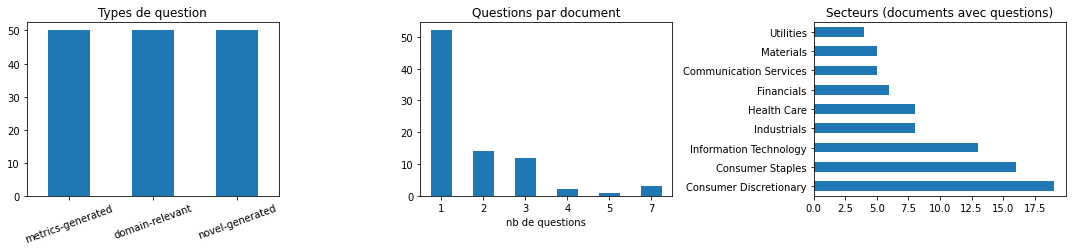

Documents avec au moins une question : 84 sur 361

Types de document couverts :
 10k         64
10q          8
8k           6
Earnings     6
Name: doc_type, dtype: int64

Exemple de question :
 What is the FY2018 capital expenditure amount (in USD millions) for 3M? Give a response to the question by relying on the details shown in the cash flow statement. 
=> réponse de référence : $1577.00


In [5]:
# 2.1 qualité de base
print("Valeurs manquantes par colonne :")
print(q.isna().sum()[q.isna().sum() > 0], "\n")
print("Doublons sur financebench_id :", q.financebench_id.duplicated().sum())
print("Sous-ensemble déclaré :", q.dataset_subset_label.unique(), "\n")

# 2.2 structure de `evidence`
print("Type de la colonne evidence :", type(q.evidence.iloc[0]).__name__)
print("Clés d'une preuve :", sorted(q.evidence.iloc[0][0].keys()))
print("Nombre de preuves par question :\n", q.evidence.apply(len).value_counts().sort_index(), "\n")

# 2.3 une table à plat : une ligne par preuve
ev = pd.DataFrame([
    dict(financebench_id=r.financebench_id, doc_name=e["doc_name"], page=e["evidence_page_num"],
         text=e["evidence_text"], full_page=e["evidence_text_full_page"])
    for r in q.itertuples() for e in r.evidence
])
print("Preuves au total :", len(ev))
mismatch = (ev.merge(q[["financebench_id", "doc_name"]], on="financebench_id", suffixes=("_ev", "_q"))
              .query("doc_name_ev != doc_name_q"))
print("Preuves dont le document diffère de celui de la question :", len(mismatch))

# 2.4 répartitions
fig, ax = plt.subplots(1, 3, figsize=(15, 3.6))
q.question_type.value_counts().plot.bar(ax=ax[0], title="Types de question", rot=20)
q.groupby("doc_name").size().value_counts().sort_index().plot.bar(ax=ax[1], title="Questions par document", xlabel="nb de questions", rot=0)
meta[meta.doc_name.isin(q.doc_name)].gics_sector.value_counts().plot.barh(ax=ax[2], title="Secteurs (documents avec questions)")
plt.tight_layout(); plt.show()

print("Documents avec au moins une question :", q.doc_name.nunique(), "sur", len(meta))
print("\nTypes de document couverts :\n", meta[meta.doc_name.isin(q.doc_name)].doc_type.value_counts())
print("\nExemple de question :\n", q.question.iloc[0], "\n=> réponse de référence :", q.answer.iloc[0])

### Lecture des résultats
À vérifier :
1. **Valeurs manquantes** : `domain_question_num` est vide pour une partie des lignes. Ce champ ne nous sert pas.
2. **Preuves par question** : la plupart des questions ont 1 preuve, certaines 2 ou 3. Notre métrique devra gérer plusieurs pages « correctes » (section 6).
3. **Questions par document** : beaucoup de documents n'ont qu'**une** question. Conséquence directe : si on choisit 12 documents au hasard, on obtient très peu de questions. On choisira donc les documents de façon plus réfléchie (section 3).
4. **Cohérence** : le document de chaque preuve doit être celui de la question (résultat attendu : 0 différence).

**Mes observations :** ...

> **À noter dans DECISIONS.md :** pourquoi la sélection ne sera pas purement aléatoire (peu de questions par document).

## 3. Sélection des documents

**Objectif :** choisir un sous-ensemble de documents qui tient sur Colab, tout en gardant assez de questions pour une évaluation significative.

**Pour comprendre :**
- Le benchmark complet utilise des centaines de PDF. On en prend ~18 pour que l'indexation reste rapide.
- Deux contraintes de conception :
  1. **Assez de questions** : on préfère les documents qui en ont plusieurs.
  2. **Distracteurs réalistes** : on garde **deux documents de la même société** (années différentes). Le système doit alors distinguer « 3M 2018 » de « 3M 2017 », ce qui est bien plus dur que de distinguer deux sociétés.
- Le tirage est fait avec `SEED` : même graine, même sélection. La liste est sauvegardée en JSON.
- **Limite à assumer** : un sous-ensemble est plus facile que le benchmark complet (moins de documents concurrents). Les scores ne sont pas comparables aux résultats publiés.

In [6]:
n_q = q.groupby("doc_name").size().rename("n_q")
cand = meta[meta.doc_name.isin(n_q.index)].merge(n_q, left_on="doc_name", right_index=True)

rng = np.random.default_rng(SEED)

# (a) sociétés avec >= 2 documents riches en questions : on garde les 2 meilleurs documents
eligible = sorted(c for c, g in cand.groupby("company") if len(g) >= 2 and g.nlargest(2, "n_q").n_q.sum() >= 4)
pair_companies = sorted(rng.choice(eligible, size=min(N_PAIR_COMPANIES, len(eligible)), replace=False).tolist())
pair_docs = [d for c in pair_companies for d in cand[cand.company == c].nlargest(2, "n_q").doc_name]

# (b) documents isolés, secteurs variés d'abord
rest = cand[~cand.company.isin(pair_companies) & (cand.n_q >= 2)].sample(frac=1, random_state=SEED)
singles, used_sectors, used_companies = [], set(), set()
for r in rest.itertuples():
    if len(singles) >= N_SINGLES: break
    if r.gics_sector not in used_sectors and r.company not in used_companies:
        singles.append(r.doc_name); used_sectors.add(r.gics_sector); used_companies.add(r.company)
for r in rest.itertuples():                       # complète si pas assez de secteurs distincts
    if len(singles) >= N_SINGLES: break
    if r.doc_name not in singles and r.company not in used_companies:
        singles.append(r.doc_name); used_companies.add(r.company)

SELECTED = pair_docs + singles
sel = cand[cand.doc_name.isin(SELECTED)].sort_values(["company", "doc_period"])
(EVAL_DIR / "selected_docs.json").write_text(json.dumps(SELECTED, indent=2))

print(f"{len(SELECTED)} documents sélectionnés, {int(sel.n_q.sum())} questions associées\n")
print(sel[["doc_name", "company", "gics_sector", "doc_type", "doc_period", "n_q"]].to_string(index=False))
print("\nSociétés avec 2 documents (distracteurs proches) :", pair_companies)

18 documents sélectionnés, 49 questions associées

                                doc_name             company            gics_sector doc_type  doc_period  n_q
                             3M_2022_10K                  3M            Industrials      10k        2022    3
                           3M_2023Q2_10Q                  3M            Industrials      10q        2023    3
             ACTIVISIONBLIZZARD_2019_10K Activision Blizzard Communication Services      10k        2019    2
                          ADOBE_2022_10K               Adobe Information Technology      10k        2022    2
                   AMCOR_2023Q4_EARNINGS               Amcor              Materials Earnings        2023    2
                        BESTBUY_2023_10K            Best Buy Consumer Discretionary      10k        2023    3
                         BOEING_2018_10K              Boeing            Industrials      10k        2018    1
                         BOEING_2022_10K              Boeing         

### Lecture des résultats
À vérifier :
- **Nombre de questions** : idéalement 40 ou plus. Avec moins, les résultats seront très instables (voir les intervalles de confiance en section 11).
- **Variété** : plusieurs secteurs, plusieurs types de document (10-K surtout, parfois 10-Q, 8-K).
- **Paires** : pour chaque société « paire », deux années différentes.

Pour changer la sélection, modifie `N_PAIR_COMPANIES`, `N_SINGLES` ou `SEED` en section 0, et note-le dans `DECISIONS.md`.

**Mes observations :** ...

## 4. Téléchargement et audit des PDF

**Objectif :** télécharger les PDF sélectionnés, extraire le texte de chaque page, et vérifier que l'extraction est exploitable.

**Pour comprendre :**
- On extrait le texte **page par page** avec PyMuPDF et on garde chaque page séparée : le numéro de page est ce qui permet de mesurer le retrieval.
- Un PDF peut être un **scan** (image sans texte). Alors l'extraction renvoie du vide et il faudrait de l'OCR. On le détecte en comptant les pages quasi vides.
- Les chiffres financiers sont dans des **tableaux** : l'extraction de texte les aplatit (une cellule par ligne). C'est une limite connue du parsing, qu'il faudra citer dans le rapport.
- Principe de robustesse : le téléchargement est **idempotent** (relancer ne retélécharge pas) et on contrôle que le fichier est bien un PDF.

In [7]:
def download_pdf(doc_name):
    path = PDF_DIR / f"{doc_name}.pdf"
    if path.exists() and path.stat().st_size > 10_000:
        return path
    r = requests.get(f"{GITHUB_RAW}pdfs/{doc_name}.pdf", timeout=120)
    if r.status_code != 200 or not r.content.startswith(b"%PDF"):
        raise RuntimeError(f"{doc_name}: HTTP {r.status_code}, contenu non PDF")
    path.write_bytes(r.content)
    return path

def extract_pages(path):
    with pymupdf.open(path) as d:
        return [p.get_text() for p in d]

PAGES, failed = {}, []
for d in SELECTED:
    try:
        PAGES[d] = extract_pages(download_pdf(d))
    except Exception as e:
        failed.append((d, str(e)))
if failed:
    raise RuntimeError(f"Échecs de téléchargement : {failed}")

audit = pd.DataFrame([
    dict(doc_name=d, n_pages=len(p), total_chars=sum(map(len, p)),
         low_text_pages=sum(len(t.strip()) < 50 for t in p))
    for d, p in PAGES.items()
])
audit["low_text_share"] = (audit.low_text_pages / audit.n_pages).round(3)
print(audit.to_string(index=False))
print("\nTotal pages :", audit.n_pages.sum(), "| Total caractères :", f"{audit.total_chars.sum():,}")

                                doc_name  n_pages  total_chars  low_text_pages  low_text_share
                             3M_2022_10K      252       927820               0           0.000
                           3M_2023Q2_10Q       92       353609               0           0.000
                         BOEING_2022_10K      190       510162               2           0.011
                         BOEING_2018_10K      136       378880               0           0.000
                      CVSHEALTH_2022_10K      213       856198               1           0.005
                      CVSHEALTH_2018_10K      392      1429606               2           0.005
                JOHNSON_JOHNSON_2022_10K      151       521914               0           0.000
JOHNSON_JOHNSON_2023_8K_dated-2023-08-30       27        57066               0           0.000
              ULTABEAUTY_2023Q4_EARNINGS        9        20570               0           0.000
                     ULTABEAUTY_2023_10K      105 

### Lecture des résultats
À vérifier :
- **`low_text_share`** (part de pages presque vides) doit être faible. S'il est élevé pour un document, c'est probablement un scan : il faudra de l'OCR ou l'exclure.
- **`n_pages`** : un 10-K fait souvent plusieurs centaines de pages ; un 8-K ou un communiqué de résultats, beaucoup moins.
- Prends une page de tableau (par exemple un compte de résultat) et affiche son texte brut : tu verras comment le tableau est aplati. C'est la raison pour laquelle les questions numériques sont les plus difficiles.

**Mes observations :** ...

In [8]:
# Mini-inspection : à quoi ressemble une page de tableau après extraction ?
doc0 = SELECTED[0]
page_demo = int(np.argmax([len(re.findall(r"\d", t)) for t in PAGES[doc0]]))   # page la plus "numérique"
print(f"{doc0} | page {page_demo} (la plus riche en chiffres)\n")
print(PAGES[doc0][page_demo][:700])

3M_2022_10K | page 74 (la plus riche en chiffres)

Table of Contents
NOTE 12. Long-Term Debt and Short-Term Borrowings
The following debt tables reflect effective interest rates, which include the impact of interest rate swaps, as of December 31, 2022. If the debt was issued on a combined basis,
the debt has been separated to show the impact of the fixed versus floating effective interest rates. Carrying value includes the impact of debt issuance costs and fair value
hedging activity. Long-term debt and short-term borrowings as of December 31 consisted of the following:
Long-Term Debt
(Millions)
Currency/ Fixed vs.
Floating
Effective Interest
Rate
Final Maturity Date
Carrying Value
Description / 2022 Principal Amount
2022
2021
Medium-term no


**Ce que tu viens de voir :** les cellules d'un tableau sont séparées par des retours à la ligne. Les libellés et les valeurs ne sont plus alignés visuellement. Un modèle d'embeddings voit une suite de chiffres, avec peu de sens. C'est une des raisons pour lesquelles on combinera une recherche lexicale (BM25) avec la recherche vectorielle.

**Mes observations :** ...

## 5. Calibration des numéros de page

**Objectif :** vérifier que le numéro de page du dataset correspond à la numérotation de PyMuPDF.

**Pour comprendre :**
- Un décalage d'une page (page 59 du dataset = page 58 ou 60 pour PyMuPDF) est un bug classique et silencieux : le système trouve la bonne page mais est compté comme faux. Résultat : des scores artificiellement bas, et des heures perdues à chercher une erreur qui n'existe pas dans le modèle.
- Plutôt que de deviner, on **mesure** : pour chaque preuve, on cherche son texte dans la page `p + décalage`, pour un décalage de −1, 0 et +1. Le bon décalage est celui qui trouve le texte presque à chaque fois.
- C'est un exemple de **validation des données** : on teste une hypothèse sur le jeu de données avant de s'en servir.

In [9]:
def norm(s):
    return re.sub(r"\s+", "", s.lower())

ev_sel = ev[ev.doc_name.isin(SELECTED)].copy()

def found_at(row, offset):
    p = row.page + offset
    pages = PAGES[row.doc_name]
    snippet = norm(row.text)[:80]
    return (0 <= p < len(pages)) and len(snippet) >= 20 and snippet in norm(pages[p])

share = {off: float(np.mean([found_at(r, off) for r in ev_sel.itertuples()])) for off in (-1, 0, 1)}
print("Part des preuves retrouvées dans la page (numéro + décalage) :")
for off, s in share.items():
    print(f"  décalage {off:+d} : {s:.1%}")

PAGE_OFFSET = max(share, key=share.get)
assert share[PAGE_OFFSET] >= 0.8, (
    f"Calibration douteuse (meilleur score {share[PAGE_OFFSET]:.1%}). "
    "Inspecte quelques preuves à la main avant de continuer.")
print(f"\n=> décalage retenu : {PAGE_OFFSET:+d}")

Part des preuves retrouvées dans la page (numéro + décalage) :
  décalage -1 : 0.0%
  décalage +0 : 98.4%
  décalage +1 : 0.0%

=> décalage retenu : +0


### Lecture des résultats
- Un décalage doit se détacher nettement (par exemple 95 % contre quelques % pour les autres). C'est lui qu'on retient.
- Si **aucun** décalage ne dépasse 80 %, le notebook s'arrête : regarde quelques preuves à la main (`ev_sel.head()`), c'est peut-être un problème d'extraction du texte (page scannée, mise en page) plutôt qu'un décalage.
- Les quelques preuves non retrouvées sont normales : le texte du dataset et l'extraction PyMuPDF peuvent différer légèrement (espaces, caractères spéciaux).

**Mes observations :** ...

> **À noter dans DECISIONS.md :** le décalage mesuré et comment tu l'as vérifié.

## 6. Vérité terrain et séparation dev / test

**Objectif :** associer à chaque question la liste des pages « correctes », puis la séparer en un jeu **dev** et un jeu **test**.

**Pour comprendre :**
- **Vérité terrain (gold)** : pour une question, l'ensemble des couples *(document, page)* qui contiennent la preuve. Le système a réussi si l'une de ces pages apparaît dans ses résultats.
- **Pourquoi deux jeux ?** Tu vas essayer plusieurs réglages (taille de chunk, poids de la fusion, nombre de candidats). Si tu les choisis en regardant les mêmes questions que celles du score final, ton score est trop optimiste : c'est de la **fuite d'information** (*data leakage*). La règle :
  - **dev** : on regarde, on règle, on se trompe, on recommence.
  - **test** : on le verrouille, on ne l'ouvre qu'**une fois**, à la fin.
- Le découpage est fait avec `SEED` puis **sauvegardé sur Drive**, pour qu'il ne change plus jamais.

In [10]:
q_sel = q[q.doc_name.isin(SELECTED)].copy().reset_index(drop=True)
ev_sel["page_adj"] = ev_sel.page + PAGE_OFFSET

gold = {}
for r in ev_sel.itertuples():
    gold.setdefault(r.financebench_id, set()).add((r.doc_name, int(r.page_adj)))
assert q_sel.financebench_id.isin(gold).all(), "Certaines questions n'ont aucune preuve"
q_sel["gold_pages"] = q_sel.financebench_id.map(lambda i: sorted(gold[i]))

perm = np.random.default_rng(SEED).permutation(len(q_sel))
n_dev = int(round(DEV_FRAC * len(q_sel)))
dev = q_sel.iloc[perm[:n_dev]].reset_index(drop=True)
test = q_sel.iloc[perm[n_dev:]].reset_index(drop=True)
assert set(dev.financebench_id).isdisjoint(test.financebench_id)

KEEP = ["financebench_id", "doc_name", "company", "question_type", "question_reasoning", "question", "answer", "gold_pages"]
dev[KEEP].to_json(EVAL_DIR / "questions_dev.jsonl", orient="records", lines=True)
test[KEEP].to_json(EVAL_DIR / "questions_test.jsonl", orient="records", lines=True)

print(f"Questions retenues : {len(q_sel)} | dev : {len(dev)} | test : {len(test)}")
print("\nTypes de question (dev | test) :")
print(pd.concat([dev.question_type.value_counts().rename("dev"), test.question_type.value_counts().rename("test")], axis=1).fillna(0).astype(int))
print("\nPages gold par question (dev) :\n", dev.gold_pages.apply(len).value_counts().sort_index())

Questions retenues : 49 | dev : 34 | test : 15

Types de question (dev | test) :
                   dev  test
novel-generated     16     6
domain-relevant     15     8
metrics-generated    3     1

Pages gold par question (dev) :
 1    27
2     7
Name: gold_pages, dtype: int64


### Lecture des résultats
À vérifier :
- **Taille des jeux** : si dev et test sont très petits (moins de 15 questions pour le test), chaque question pèse plusieurs points de pourcentage. Ce sera visible dans les intervalles de confiance.
- Les trois types de question (`metrics-generated`, `domain-relevant`, `novel-generated`) sont présents dans les deux jeux.
- Les fichiers `questions_dev.jsonl` et `questions_test.jsonl` sont sur Drive : **ne les régénère plus** une fois que tu as commencé à régler.

**Mes observations :** ...

> **À noter dans DECISIONS.md :** ratio dev/test (70/30), la graine, et la règle « le test n'est ouvert qu'une fois ».

## 7. Découpage en chunks

**Objectif :** découper chaque page en morceaux de taille adaptée à la recherche, en gardant l'origine de chaque morceau.

**Pour comprendre :**
- Un LLM et un modèle d'embeddings ne traitent pas un document entier : on le découpe en **chunks**. Trop gros, le sens se dilue (un vecteur pour trop d'idées). Trop petit, on perd le contexte.
- **Chevauchement** (*overlap*) : chaque chunk reprend la fin du précédent, pour qu'une phrase coupée en deux reste lisible dans au moins un chunk.
- Chaque chunk garde ses **métadonnées** : `doc` et `page`. C'est ce qui permet de calculer le recall@k et de citer la source.
- **En-tête contextuel** (`ADD_HEADER`) : on ajoute `[doc | page N]` au début du texte du chunk. Pourquoi ? Une question comme *« capex 2018 de 3M »* contient le nom de la société et l'année, mais le texte d'une page de tableau, lui, ne les répète pas. L'en-tête rend cette information disponible à la recherche. C'est un choix de conception à tester en ablation (voir section 14).
- Les pages sont numérotées **à partir de 0**, comme PyMuPDF.

9,131 chunks | longueur médiane 1200 caractères
Chunks par page : 3.9 en moyenne


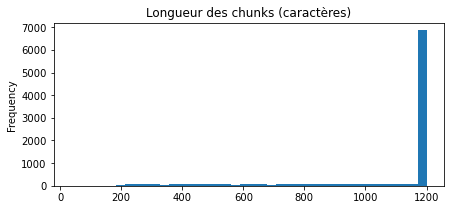


Exemple de chunk :
[CVSHEALTH_2018_10K | page 317]
prescription claim are considered part of a single performance obligation which culminates in the dispensing of prescription drugs.
The Company recognizes revenue using the gross method at the contract price negotiated with its clients when the Company has concluded it controls the
prescription drug before it is transferred to the client plan members. The Company controls prescriptions dispensed indirectly through its retail pharmacy network
because it has separat

Pages gold sans aucun chunk (page vide / scan) : 0 sur 53


In [11]:
def make_chunks(pages_by_doc, size, overlap, header):
    chunks, step = [], size - overlap
    for doc, pages in pages_by_doc.items():
        for p, text in enumerate(pages):
            text = re.sub(r"[ \t]+", " ", text).strip()
            if len(text) < 30:
                continue
            for s in range(0, len(text), step):
                piece = text[s:s + size].strip()
                if len(piece) < 30:
                    continue
                head = f"[{doc} | page {p}]\n" if header else ""
                chunks.append(dict(doc=doc, page=p, start=s, raw=piece, text=head + piece))
                if s + size >= len(text):
                    break
    return chunks

chunks = make_chunks(PAGES, CHUNK_SIZE, CHUNK_OVERLAP, ADD_HEADER)
lens = pd.Series([len(c["raw"]) for c in chunks])
print(f"{len(chunks):,} chunks | longueur médiane {int(lens.median())} caractères")
print(f"Chunks par page : {len(chunks) / audit.n_pages.sum():.1f} en moyenne")
ax = lens.plot.hist(bins=40, figsize=(7, 3), title="Longueur des chunks (caractères)")
plt.show()
print("\nExemple de chunk :\n" + chunks[len(chunks)//2]["text"][:500])

# les pages gold existent-elles dans nos chunks ? (sinon le recall maximal est < 100 %)
chunk_pages = {(c["doc"], c["page"]) for c in chunks}
all_gold = {g for gs in q_sel.gold_pages for g in map(tuple, gs)}
missing = all_gold - chunk_pages
print(f"\nPages gold sans aucun chunk (page vide / scan) : {len(missing)} sur {len(all_gold)}")

### Lecture des résultats
À vérifier :
- **Pages gold sans chunk** : doit être 0 ou presque. Si non, une partie des questions est *impossible* à réussir par construction (le score maximal n'est pas 100 %), et il faut le dire dans le rapport.
- **Histogramme** : la plupart des chunks sont proches de 1200 caractères ; un pic plus petit correspond aux fins de page.
- Combien de chunks par page ? Plus il y en a, plus l'index est gros et plus le reranker travaille.

**Mes observations :** ...

## 8. Embeddings et index vectoriel

**Objectif :** transformer chaque chunk en vecteur et le stocker dans une base vectorielle persistante.

**Pour comprendre :**
- Un **embedding** transforme un texte en une liste de nombres (un vecteur) telle que deux textes de sens proche donnent des vecteurs proches. La recherche vectorielle revient à : *trouver les chunks dont le vecteur est le plus proche de celui de la question*.
- Le modèle `bge-base-en-v1.5` est un bon compromis qualité / vitesse pour l'anglais. (Pour les rapports tunisiens en français, on prendra un modèle multilingue dans un notebook suivant.)
- Pour les modèles BGE, la **question** reçoit un préfixe d'instruction (`QUERY_PREFIX`), pas les passages. C'est la façon dont le modèle a été entraîné.
- **Similarité cosinus** : on normalise les vecteurs, le produit scalaire mesure alors l'angle entre eux.
- **Base vectorielle (Chroma)** : stocke les vecteurs et trouve rapidement les plus proches. Elle est écrite sur Drive : à la prochaine session, on recharge sans recalculer.
- Le nom de la collection contient les paramètres de découpage : si tu changes la taille de chunk, un **nouvel** index est créé au lieu de réutiliser un index périmé.

In [12]:
if not USE_MODELS:
    print("Mode léger : pas d'embeddings ni d'index vectoriel (voir section 0.3).")
else:
    from sentence_transformers import SentenceTransformer
    import chromadb

    embedder = SentenceTransformer(EMB_MODEL, device=DEVICE)
    client = chromadb.PersistentClient(path=str(IDX_DIR))
    COLLECTION = f"fb_c{CHUNK_SIZE}_o{CHUNK_OVERLAP}_h{int(ADD_HEADER)}_{len(SELECTED)}docs"

    col = client.get_or_create_collection(COLLECTION, metadata={"hnsw:space": "cosine"})
    if col.count() != len(chunks):
        client.delete_collection(COLLECTION)
        col = client.create_collection(COLLECTION, metadata={"hnsw:space": "cosine"})
        t0 = time.time()
        embs = embedder.encode([c["text"] for c in chunks], batch_size=64,
                               normalize_embeddings=True, show_progress_bar=True)
        for i in range(0, len(chunks), 1000):
            j = min(i + 1000, len(chunks))
            col.add(ids=[str(k) for k in range(i, j)], embeddings=embs[i:j].tolist(),
                    metadatas=[{"doc": c["doc"], "page": c["page"]} for c in chunks[i:j]])
        print(f"Index construit en {time.time() - t0:.0f} s")
    else:
        print("Index déjà présent sur Drive : rechargé sans recalcul")
    print(f"Collection '{COLLECTION}' : {col.count():,} vecteurs, dimension {embedder.get_sentence_embedding_dimension()}")

Mode léger : pas d'embeddings ni d'index vectoriel (voir section 0.3).


### Lecture des résultats
**En mode léger, cette section est volontairement ignorée** (message affiché, aucun calcul).

En mode complet, à vérifier :
- Le nombre de vecteurs est **égal** au nombre de chunks de la section 7.
- Note le **temps de construction** (utile pour le rapport : coût d'indexation).
- Relance la cellule : elle doit afficher « Index déjà présent » en quelques secondes. C'est la persistance sur Drive qui fonctionne.

**Mes observations (temps d'indexation, nombre de vecteurs) :** ...

## 9. Les stratégies de retrieval

**Objectif :** implémenter les méthodes de recherche que l'on pourra comparer à armes égales (cinq en mode complet, deux en mode léger : `random` et `bm25`).

**Pour comprendre :**

| Méthode | Principe | Force | Faiblesse |
|---|---|---|---|
| **random** | chunks tirés au hasard | repère minimal : un système qui ne fait pas mieux ne sert à rien | — |
| **bm25** | recherche **lexicale** : score selon les mots communs entre question et chunk (rares = plus importants) | très bon sur les termes exacts, sigles, noms propres, chiffres | ne comprend pas les synonymes |
| **dense** | recherche **vectorielle** : proximité de sens | comprend les reformulations | peut rater un terme exact |
| **hybrid** | fusionne les classements de BM25 et dense avec la **RRF** (Reciprocal Rank Fusion) | combine les deux forces | un peu plus complexe |
| **hybrid+rerank** | un **cross-encoder** relit chaque couple (question, chunk) et reclasse les meilleurs candidats | plus précis | plus lent (un calcul par candidat) |

- **RRF** : chaque chunk reçoit `1 / (k + rang)` dans chaque liste, et on additionne. Un chunk bien classé dans les deux listes monte tout en haut. Avantage : on n'a pas besoin de comparer des scores d'échelles différentes, seulement des **rangs**.
- **Bi-encodeur vs cross-encodeur** : l'embedding (bi-encodeur) encode question et chunk *séparément* : rapide, mais approximatif. Le cross-encodeur lit la question et le chunk *ensemble* : plus précis, trop lent pour tout l'index, d'où son rôle de **deuxième étape** sur 30 candidats seulement.

In [13]:
from rank_bm25 import BM25Okapi

# --- BM25 (toujours disponible, aucun paquet lourd) ---
def tokenize(t):
    return re.findall(r"\w+", t.lower())

bm25 = BM25Okapi([tokenize(c["text"]) for c in chunks])

# --- les méthodes : chacune renvoie une liste d'indices de chunks, du meilleur au moins bon ---
def r_random(query, n=TOP_N):
    seed = int(hashlib.md5(query.encode()).hexdigest(), 16) % (2**32)   # stable d'une session à l'autre
    return np.random.default_rng(seed).permutation(len(chunks))[:n].tolist()

def r_bm25(query, n=TOP_N):
    scores = bm25.get_scores(tokenize(query))
    return np.argsort(-scores)[:n].tolist()

RETRIEVERS = {"random": r_random, "bm25": r_bm25}

# --- méthodes avec modèles (mode complet uniquement) ---
if USE_MODELS:
    from sentence_transformers import CrossEncoder
    reranker = CrossEncoder(RERANK_MODEL, device=DEVICE, max_length=512)

    def r_dense(query, n=TOP_N):
        qe = embedder.encode([QUERY_PREFIX + query], normalize_embeddings=True)
        res = col.query(query_embeddings=qe.tolist(), n_results=min(n, col.count()))
        return [int(i) for i in res["ids"][0]]

    def rrf(rank_lists, k=RRF_K, n=TOP_N):
        s = {}
        for rl in rank_lists:
            for r, i in enumerate(rl):
                s[i] = s.get(i, 0.0) + 1.0 / (k + r + 1)
        return [i for i, _ in sorted(s.items(), key=lambda x: -x[1])[:n]]

    def r_hybrid(query, n=TOP_N):
        return rrf([r_dense(query), r_bm25(query)], n=n)

    def r_hybrid_rerank(query, n=TOP_N):
        cand = r_hybrid(query, n=RERANK_TOP)
        sc = reranker.predict([(query, chunks[i]["text"]) for i in cand], batch_size=32, show_progress_bar=False)
        return [cand[j] for j in np.argsort(-sc)]

    RETRIEVERS.update({"dense": r_dense, "hybrid": r_hybrid, "hybrid+rerank": r_hybrid_rerank})
else:
    print("Mode léger : seules les méthodes 'random' et 'bm25' sont disponibles.")

print("Méthodes disponibles :", list(RETRIEVERS))

# test rapide sur une question
qtest = dev.question.iloc[0]
print("\nQuestion :", qtest, "\nGold :", dev.gold_pages.iloc[0], "\n")
for name, fn in RETRIEVERS.items():
    top = [(chunks[i]["doc"], chunks[i]["page"]) for i in fn(qtest)[:3]]
    print(f"{name:14s} top-3 -> {top}")

Mode léger : seules les méthodes 'random' et 'bm25' sont disponibles.
Méthodes disponibles : ['random', 'bm25']

Question : What is the FY2018 fixed asset turnover ratio for CVS Health? Fixed asset turnover ratio is defined as: FY2018 revenue / (average PP&E between FY2017 and FY2018). Round your answer to two decimal places. Calculate what was asked by utilizing the line items clearly shown in the P&L statement and the balance sheet. 
Gold : [('CVSHEALTH_2018_10K', 301), ('CVSHEALTH_2018_10K', 303)] 

random         top-3 -> [('JOHNSON_JOHNSON_2022_10K', 40), ('CVSHEALTH_2018_10K', 204), ('BOEING_2022_10K', 64)]
bm25           top-3 -> [('3M_2022_10K', 57), ('CVSHEALTH_2018_10K', 112), ('ULTABEAUTY_2023_10K', 61)]


### Lecture des résultats
Sur cette seule question, compare le top-3 de chaque méthode avec la page gold. **Ne conclus rien sur une question** : c'est seulement un test que tout fonctionne. L'évaluation sérieuse porte sur toutes les questions (sections 10 et 11).

Une remarque : le reranker travaille sur les 30 meilleurs candidats de l'hybride. Il ne peut donc **jamais** remonter une page qui n'est pas dans ces 30. Son recall est borné par celui de l'hybride à 30. Garde cette idée pour l'analyse d'erreurs.

**Mes observations :** ...

## 10. Les métriques

**Objectif :** définir comment on mesure la qualité du retrieval.

**Pour comprendre :**
- **Recall@k** : part des questions pour lesquelles *au moins une* page gold apparaît parmi les **k** premiers chunks. Recall@5 = 0,6 signifie : pour 60 % des questions, la bonne page est dans le top 5.
- **MRR** (Mean Reciprocal Rank) : moyenne de `1 / rang` de la première bonne page. Premier rang = 1, deuxième = 0,5, absente = 0. Il récompense de placer la bonne page **tout en haut**.
- **doc_hit@10** : le bon *document* est-il dans le top 10 ? Une métrique **de diagnostic** : si le recall de page est bas mais le doc_hit élevé, le système trouve la bonne société et la bonne année, mais pas la bonne page. Si le doc_hit est bas, il se trompe de document (société ou année).
- **Intervalle de confiance (bootstrap)** : avec ~30 questions, un score de 60 % peut très bien valoir 45 % ou 75 % avec un autre échantillon. On rééchantillonne les questions 2 000 fois pour estimer cette incertitude. Deux méthodes dont les intervalles se chevauchent largement ne sont **pas** démontrées différentes.
- On mesure au niveau des **chunks** : le top-k contient k chunks, pas k pages différentes.

In [14]:
def run_retriever(fn, df):
    rows = []
    for r in df.itertuples():
        ranked = fn(r.question)
        gold = {tuple(g) for g in r.gold_pages}
        gold_docs = {g[0] for g in gold}
        page_rank = doc_rank = np.inf
        for k, i in enumerate(ranked, 1):
            c = chunks[i]
            if doc_rank == np.inf and c["doc"] in gold_docs:
                doc_rank = k
            if (c["doc"], c["page"]) in gold:
                page_rank = k
                break
        rows.append((r.financebench_id, page_rank, doc_rank))
    return pd.DataFrame(rows, columns=["id", "page_rank", "doc_rank"])

def summarize(rk):
    out = {f"recall@{k}": float((rk.page_rank <= k).mean()) for k in KS}
    out["MRR"] = float(np.where(np.isfinite(rk.page_rank), 1.0 / rk.page_rank, 0.0).mean())
    out["doc_hit@10"] = float((rk.doc_rank <= 10).mean())
    return out

def bootstrap_ci(hits, n_boot=2000, seed=SEED):
    hits = np.asarray(hits, dtype=float)
    rng = np.random.default_rng(seed)
    means = [rng.choice(hits, size=len(hits), replace=True).mean() for _ in range(n_boot)]
    return float(np.percentile(means, 2.5)), float(np.percentile(means, 97.5))

# test des métriques sur un cas fabriqué à la main (vérification du code lui-même)
_t = pd.DataFrame({"page_rank": [1, 3, 7, np.inf], "doc_rank": [1, 1, 2, np.inf]})
_s = summarize(_t)
assert _s["recall@1"] == 0.25 and _s["recall@3"] == 0.5 and _s["recall@10"] == 0.75
assert abs(_s["MRR"] - (1 + 1/3 + 1/7) / 4) < 1e-9
print("Tests de métriques : OK")

Tests de métriques : OK


### Lecture des résultats
Les `assert` vérifient que **ton code de métriques est correct** sur un exemple dont tu connais la réponse (4 questions : rangs 1, 3, 7 et jamais trouvé). C'est une bonne pratique : on teste l'outil de mesure avant de mesurer.

Vérifie à la main : recall@1 = 1/4 = 0,25 ; recall@3 = 2/4 = 0,5 ; recall@10 = 3/4 = 0,75.

**Mes observations :** ...

## 11. Résultats sur le jeu dev

**Objectif :** comparer toutes les méthodes sur le même jeu de questions et produire le tableau d'ablation.

**Pour comprendre :**
- Une **ablation** compare des variantes qui ne diffèrent que par une brique. Ici : dense seul → + BM25 → + reranker. Chaque ligne du tableau répond à *« cette brique apporte-t-elle quelque chose ? »*.
- **Mode léger** : seules `random` et `bm25` sont comparées. C'est déjà instructif : `bm25` doit nettement battre `random`, et ce résultat devient ta **première baseline mesurée**, que les méthodes avec modèles devront dépasser.
- **Baselines** : `random` (plancher) et `dense` (la référence à battre, en mode complet). Le but du projet est de montrer que `hybrid+rerank` fait mieux que `dense`, **ou** de montrer honnêtement que ce n'est pas le cas.
- On regarde aussi les résultats **par type de question** : une méthode peut être meilleure en moyenne et pire sur un type précis.

Évaluation terminée en 2 s sur 34 questions

       recall@1 recall@3 recall@5 recall@10    MRR doc_hit@10 recall@5 IC95%
random    0.000    0.000    0.000     0.000  0.002      0.294  [0.00 ; 0.00]
bm25      0.235    0.235    0.265     0.324  0.257      0.853  [0.12 ; 0.41]


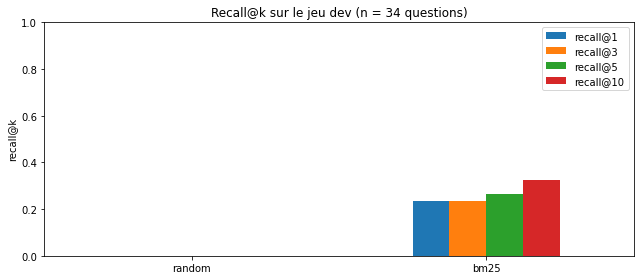


recall@5 par type de question :
                   random  bm25
question_type                  
domain-relevant       0.0  0.20
metrics-generated     0.0  0.00
novel-generated       0.0  0.38

Nombre de questions par type :
 novel-generated      16
domain-relevant      15
metrics-generated     3


In [15]:
t0 = time.time()
RANKS = {name: run_retriever(fn, dev) for name, fn in RETRIEVERS.items()}
print(f"Évaluation terminée en {time.time() - t0:.0f} s sur {len(dev)} questions\n")

table = pd.DataFrame({name: summarize(rk) for name, rk in RANKS.items()}).T
ci = {name: bootstrap_ci((rk.page_rank <= 5).values) for name, rk in RANKS.items()}
table["recall@5 IC95%"] = [f"[{lo:.2f} ; {hi:.2f}]" for lo, hi in ci.values()]
display_table = table.copy()
for c in display_table.columns[:-1]:
    display_table[c] = display_table[c].map(lambda v: f"{v:.3f}")
print(display_table.to_string())

# graphique
fig, ax = plt.subplots(figsize=(9, 4))
cols = [f"recall@{k}" for k in KS]
table[cols].plot.bar(ax=ax, rot=0, ylim=(0, 1))
ax.set_title(f"Recall@k sur le jeu dev (n = {len(dev)} questions)")
ax.set_ylabel("recall@k"); ax.legend(title="")
plt.tight_layout(); plt.show()

# par type de question
dev_ranks = dev[["financebench_id", "question_type"]].rename(columns={"financebench_id": "id"})
by_type = {}
for name, rk in RANKS.items():
    m = rk.merge(dev_ranks, on="id")
    by_type[name] = (m.page_rank <= 5).groupby(m.question_type).mean()
print("\nrecall@5 par type de question :")
print(pd.DataFrame(by_type).round(2).to_string())
print("\nNombre de questions par type :\n", dev.question_type.value_counts().to_string())

### Lecture des résultats
Interprète le tableau dans cet ordre :
1. **`random`** doit être proche de zéro. Si ce n'est pas le cas, il y a un problème (trop peu de chunks, ou une fuite).
2. **`dense` vs `bm25`** : lequel est meilleur sur ce corpus ? Les chiffres et noms propres favorisent BM25 ; les reformulations favorisent le dense.
3. **`hybrid` vs le meilleur des deux** : la fusion doit être au moins aussi bonne que sa meilleure composante.
4. **`hybrid+rerank` vs `hybrid`** : le reranker améliore-t-il le recall@1 et le MRR (ordre du haut du classement) ? Son effet est surtout visible sur les petits k.
5. **Intervalles de confiance** : s'ils se chevauchent beaucoup, **ne prétends pas** qu'une méthode est meilleure. Écris plutôt « tendance, non significative avec n questions ».
6. **Par type de question** : avec très peu de questions par type, ces chiffres sont indicatifs seulement.

**Mes observations (quelle méthode gagne ? l'écart est-il significatif ?) :** ...

> **À noter dans DECISIONS.md :** la configuration retenue pour la suite, et la raison chiffrée.

## 12. Analyse d'erreurs

**Objectif :** comprendre *pourquoi* le meilleur système échoue, question par question.

**Pour comprendre :**
- Un score global dit *combien* le système échoue, pas *pourquoi*. L'analyse d'erreurs est ce qui distingue un projet sérieux d'un tableau de chiffres.
- Trois causes typiques à chercher :
  1. **Mauvais document** (`doc_hit@10` faux) : confusion de société ou d'année.
  2. **Bon document, mauvaise page** : la page de tableau est noyée parmi d'autres pages semblables (par exemple plusieurs tableaux financiers).
  3. **Question trop vague ou page mal extraite** : rien à reprocher au système.
- Ce qu'on peut en déduire : une cause (1) suggère un filtrage par société/année ou un meilleur en-tête ; une cause (2) suggère un chunking par tableau ou un meilleur reranker.

In [16]:
BEST = max(RANKS, key=lambda n: (summarize(RANKS[n])["recall@5"], summarize(RANKS[n])["MRR"]))
print("Meilleure méthode sur dev (recall@5 puis MRR) :", BEST, "\n")

errs = RANKS[BEST].merge(dev[["financebench_id", "question", "gold_pages", "question_type"]],
                         left_on="id", right_on="financebench_id")
errs = errs[errs.page_rank > 5]
print(f"{len(errs)} questions sur {len(dev)} sans la bonne page dans le top 5\n")

def cause(r):
    if r.doc_rank > 10:
        return "mauvais document"
    return "bon document, mauvaise page"

errs = errs.assign(cause=errs.apply(cause, axis=1))
print(errs.cause.value_counts().to_string(), "\n")

for r in errs.head(8).itertuples():
    top3 = [(chunks[i]["doc"], chunks[i]["page"]) for i in RETRIEVERS[BEST](r.question)[:3]]
    print("-" * 90)
    print("Q     :", r.question[:220])
    print("GOLD  :", [tuple(g) for g in r.gold_pages])
    print("TOP-3 :", top3)
    print("CAUSE :", r.cause, "| rang de la bonne page :", "non trouvée" if np.isinf(r.page_rank) else int(r.page_rank))

Meilleure méthode sur dev (recall@5 puis MRR) : bm25 

25 questions sur 34 sans la bonne page dans le top 5

bon document, mauvaise page    20
mauvais document                5 

------------------------------------------------------------------------------------------
Q     : What is the FY2018 fixed asset turnover ratio for CVS Health? Fixed asset turnover ratio is defined as: FY2018 revenue / (average PP&E between FY2017 and FY2018). Round your answer to two decimal places. Calculate what w
GOLD  : [('CVSHEALTH_2018_10K', 301), ('CVSHEALTH_2018_10K', 303)]
TOP-3 : [('3M_2022_10K', 57), ('CVSHEALTH_2018_10K', 112), ('ULTABEAUTY_2023_10K', 61)]
CAUSE : bon document, mauvaise page | rang de la bonne page : non trouvée
------------------------------------------------------------------------------------------
Q     : Does Verizon have a reasonably healthy liquidity profile based on its quick ratio for FY 2022? If the quick ratio is not relevant to measure liquidity, please state that and

### Lecture des résultats
Pour chaque échec affiché, réponds toi-même :
- La société et l'année sont-elles dans la question ? Le système a-t-il choisi un document de la bonne société mais d'une autre année ?
- La page gold est-elle une page de tableau pur ? (alors le texte extrait est pauvre en mots.)
- La question est-elle ambiguë, même pour un humain ?

**Mes observations (3 échecs analysés à la main) :**
1. ...
2. ...
3. ...

> **À noter dans DECISIONS.md :** les causes d'erreur dominantes et l'amélioration que tu en déduis. C'est le matériau de la section « Limites » du rapport.

## 13. Évaluation finale sur le jeu test (verrouillée)

**Objectif :** produire les chiffres définitifs, ceux qui iront dans le rapport et sur le CV.

**Pour comprendre :**
- Le jeu test sert **une seule fois**, **après** avoir figé la configuration. Si tu le relances pour « voir si ça marche mieux avec ce réglage », il devient un second jeu dev et tes chiffres ne valent plus rien.
- La cellule ci-dessous est protégée par le drapeau `RUN_TEST` de la section 0, volontairement à `False`.
- **Avant de passer `RUN_TEST = True`**, vérifie que :
  1. tu as fini tous les réglages sur dev ;
  2. la configuration finale est écrite dans `DECISIONS.md` ;
  3. tu es prêt à rapporter le résultat, même s'il est moins bon que sur dev.
- Un résultat test **inférieur** au dev est normal (le dev a servi à régler) et même plus honnête.

In [17]:
if RUN_TEST:
    RANKS_TEST = {name: run_retriever(fn, test) for name, fn in RETRIEVERS.items()}
    table_test = pd.DataFrame({name: summarize(rk) for name, rk in RANKS_TEST.items()}).T
    ci_t = {name: bootstrap_ci((rk.page_rank <= 5).values) for name, rk in RANKS_TEST.items()}
    table_test["recall@5 IC95%"] = [f"[{lo:.2f} ; {hi:.2f}]" for lo, hi in ci_t.values()]
    table_test.to_csv(RES_DIR / "test_results.csv")
    print(f"RÉSULTATS TEST (n = {len(test)} questions)\n")
    print(table_test.round(3).to_string())
else:
    print("Jeu test verrouillé (RUN_TEST = False). C'est voulu : on ne l'ouvre qu'à la fin.")

Jeu test verrouillé (RUN_TEST = False). C'est voulu : on ne l'ouvre qu'à la fin.


### Lecture des résultats
Compare les chiffres test et dev. Un petit écart est normal. Un grand écart signale soit un jeu test très petit (donc bruité), soit un surapprentissage de tes réglages sur dev.

**Mes observations :** ...

## 14. Sauvegarde et conclusion

**Objectif :** sauvegarder les résultats, et écrire ce que tu as appris.

**Pour comprendre :** un notebook de data science ne se termine pas par du code mais par une **conclusion** : qu'est-ce qui a marché, qu'est-ce qui n'a pas marché, et qu'est-ce qu'on fait ensuite. Les fichiers de résultats servent à construire le graphique et le tableau du rapport sans relancer le notebook.

In [18]:
table.to_csv(RES_DIR / "dev_results.csv")
pd.concat({n: rk for n, rk in RANKS.items()}, names=["method"]).reset_index(level=0).to_csv(RES_DIR / "dev_ranks.csv", index=False)
print("Fichiers sauvegardés dans", RES_DIR.resolve())
for f in sorted(RES_DIR.iterdir()):
    print(" -", f.name, f"({f.stat().st_size / 1024:.0f} Ko)")
print("\nFichiers d'évaluation :", [f.name for f in sorted(EVAL_DIR.iterdir())])

Fichiers sauvegardés dans /home/cd9cacb7-c7af-487a-bd59-e254c9cb864f/RAG-Financier/results
 - config.json (1 Ko)
 - dev_ranks.csv (2 Ko)
 - dev_results.csv (0 Ko)
 - figures (4 Ko)

Fichiers d'évaluation : ['.gitkeep', 'questions_dev.jsonl', 'questions_test.jsonl', 'selected_docs.json']


### Conclusion (à rédiger toi-même)

**Résultat principal (une phrase, avec les chiffres mesurés) :**
> Sur *N* questions dev, la méthode ... atteint un recall@5 de ... [IC95 % ... ; ...] contre ... pour la recherche vectorielle seule.

**Ce qui a bien marché :** ...

**Ce qui n'a pas marché ou m'a surpris :** ...

**Limites de cette évaluation :**
- Sous-ensemble de *N* documents, plus facile que le benchmark complet : scores non comparables aux résultats publiés.
- Peu de questions : intervalles de confiance larges.
- Extraction PDF : tableaux aplatis.
- Métrique au niveau de la page : elle ne vérifie pas que la réponse finale est correcte (notebook 02).

### Expériences à faire ensuite (chacune avec un avant/après sur dev)
1. **Ablation de l'en-tête** : `ADD_HEADER = False`. Combien de points le contexte `[doc | page]` apporte-t-il ?
2. **Taille de chunk** : 600, 1200, 2000. Y a-t-il un optimum ?
3. **Poids de la fusion** : et si on ne gardait que 20 candidats par méthode ?
4. **Modèle d'embeddings** : comparer deux modèles sur dev.

### Feuille de route
- **Notebook 02** : génération de réponses avec citations et refus contrôlé, évaluation de la fidélité (RAGAS ou DeepEval).
- **Notebook 03** : rapports annuels tunisiens en français (modèle d'embeddings multilingue, parsing plus difficile, éventuellement OCR).
- **Ensuite** : migrer le code vers `src/*.py` sur GitHub, API FastAPI, Docker, déploiement.